## Customer Segmentation model

#### Import libraries

In [30]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import IsolationForest
from scipy.cluster.hierarchy import dendrogram,linkage


##### Load And Inspect Data

In [3]:
#load dataset
ds =pd.read_csv('Mall_Customers.csv')
ds.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
#correct spelling in column name
ds = ds.rename(columns={'Genre': 'Gender'})
ds


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [5]:
#inspect dataset

ds.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [6]:
#data set summary

ds.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [7]:
#check for missing values
ds.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [8]:
#inspect columns
ds.columns.tolist()

['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

### Data  Visualisation

Text(0.5, 1.0, 'Spending Score Distribution')

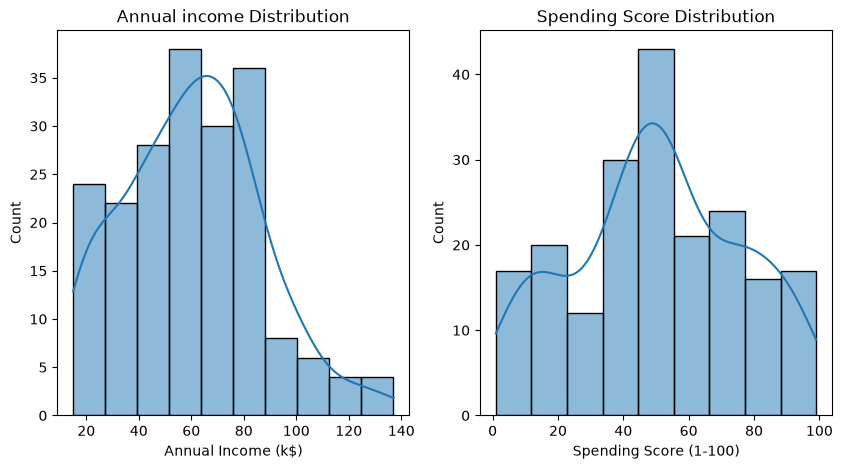

In [9]:
plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
sns.histplot(ds['Annual Income (k$)'], kde=True)
plt.title('Annual income Distribution')

plt.subplot(1,2,2)
sns.histplot(ds['Spending Score (1-100)'], kde=True)
plt.title("Spending Score Distribution")


##### Feature Engineering

In [10]:
X = ds[['Annual Income (k$)', 'Spending Score (1-100)']]
X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [11]:
#scaling
scaler = StandardScaler() #initializes scaler

#scaler learns and transforms selected features
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

#### Determine Number of clusters

In [12]:
wcss =[]
for k in range(1,21):
    kmeans = KMeans(n_clusters=k,random_state=42)
    kmeans.fit(X_scaled)  #learns from scaled data
    wcss.append(kmeans.inertia_)
print(kmeans)

KMeans(n_clusters=20, random_state=42)


Text(0, 0.5, 'WCSS')

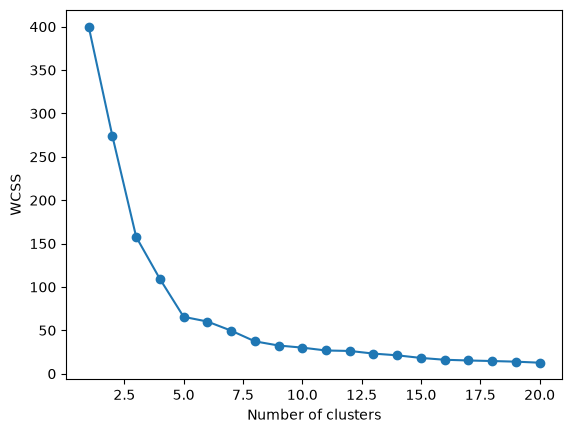

In [13]:
#plot the elbow curve
plt.plot(range(1,21),wcss,marker ='o')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')


#### Train K-Means Model

In [14]:
kmeans =KMeans(n_clusters= 5, random_state=42) #initialize kmaeans
clusters =kmeans.fit_predict(X_scaled)


In [15]:
#adding clusters column to the dataset
ds['Clusters'] = clusters
ds.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Clusters
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


#### Visualize The Clusters

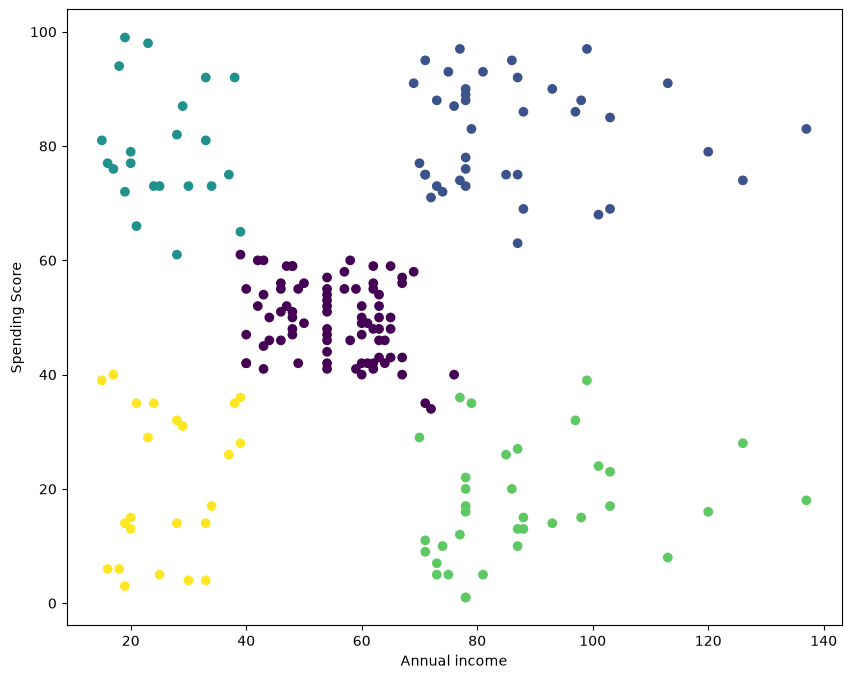

In [16]:
plt.figure(figsize=(10,8))
plt.scatter(ds['Annual Income (k$)'],
            ds['Spending Score (1-100)'],
            c =ds['Clusters']
            )
plt.xlabel('Annual income')
plt.ylabel('Spending Score')
plt.show()

#### Model Evaluation

* Silohuette Score

In [17]:
score =silhouette_score(X_scaled,ds['Clusters'])
score

0.5546571631111091

* Getting The Mean of the Clusters

In [18]:
#getting the cluster mean

ds.groupby('Clusters')[[
    'Annual Income (k$)',
    'Spending Score (1-100)'
    ]].mean()

,Annual Income (k$),Spending Score (1-100)
Clusters,,
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


* Value Counts of Elbow Clustser

In [19]:
ds['Clusters'].value_counts().sort_index(ascending =True)

Clusters
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

#### Hierachical Clustering

* Dendogram 

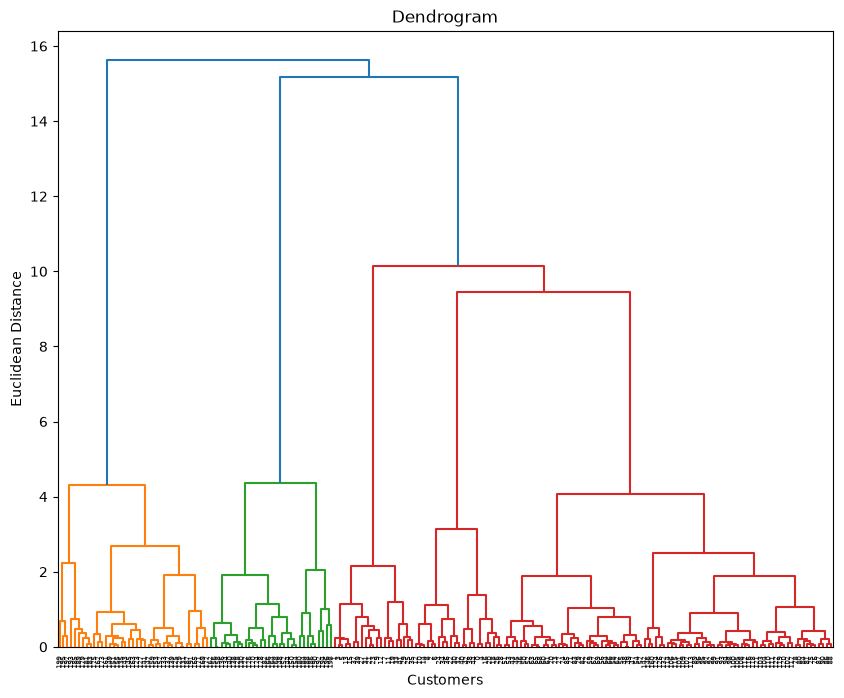

In [20]:
plt.figure(figsize = (10,8))

dendrogram(
    linkage(X_scaled, method ='ward')
)
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distance')
plt.show()


* Training the hierachical clustering model

In [21]:
hierachy = AgglomerativeClustering(
    n_clusters=4,
    metric='euclidean',
    linkage='ward'
)

hc_clusters = hierachy.fit_predict(X_scaled)

* add hierachical clusters to dataset

In [22]:
ds['Hierachical clusters'] = hc_clusters
ds.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Clusters,Hierachical clusters
0,1,Male,19,15,39,4,0
1,2,Male,21,15,81,2,3
2,3,Female,20,16,6,4,0
3,4,Female,23,16,77,2,3
4,5,Female,31,17,40,4,0


#### Visualize Hierachical Clusters

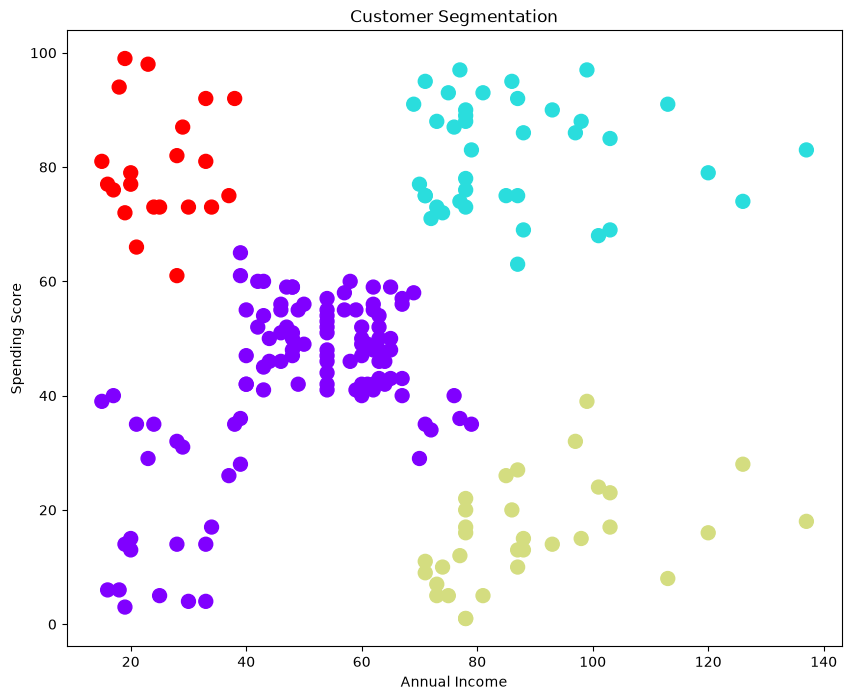

In [23]:
plt.figure(figsize=(10,8))

plt.scatter(
    ds['Annual Income (k$)'],
    ds['Spending Score (1-100)'],
    c = ds['Hierachical clusters'],
    cmap ='rainbow',
    s =100
)
plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Customer Segmentation')
plt.show()

* Evaluating HC Silohuette Score

In [24]:
hc_score = silhouette_score(X_scaled, ds['Hierachical clusters'])
hc_score

0.4925507715349343

* Getting The HC mean

In [25]:
ds.groupby('Hierachical clusters')[[
    'Annual Income (k$)',
    'Spending Score (1-100)'
]].mean()

,Annual Income (k$),Spending Score (1-100)
Hierachical clusters,,
0,49.527778,43.120370
1,86.538462,82.128205
2,89.406250,15.593750
3,25.095238,80.047619


#### OUTLIERS

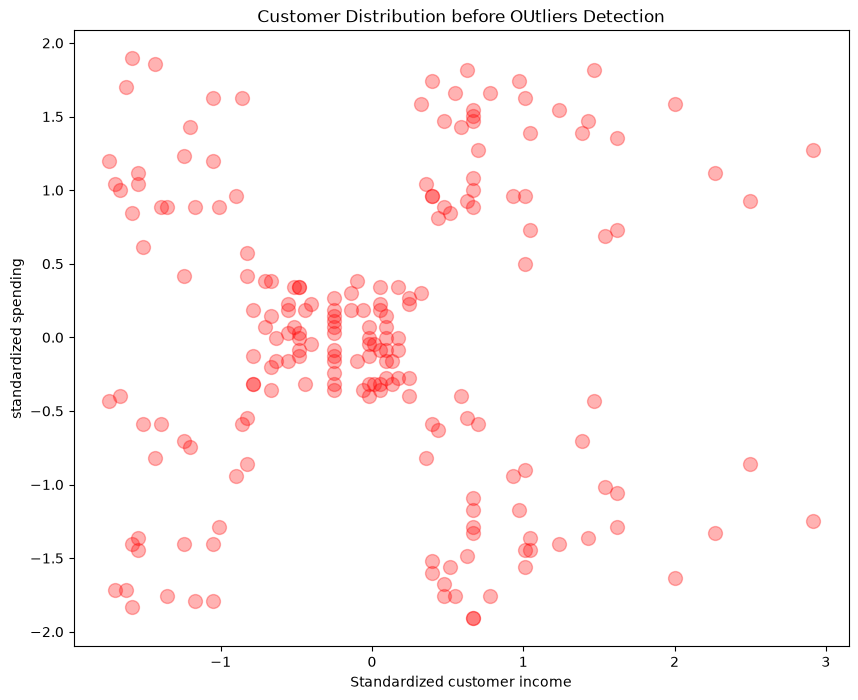

In [26]:
plt.figure(figsize = (10,8))
plt.scatter(
X_scaled[:,0],
X_scaled[:,1],
alpha = 0.3,
c = 'r',
s=100
)
plt.xlabel('Standardized customer income')
plt.ylabel('standardized spending')
plt.title('Customer Distribution before OUtliers Detection')
plt.show()


* Isolation Forest

In [27]:
#initialize
iso_forest = IsolationForest(
    n_estimators = 150,
    contamination = 0.05, 
    random_state= 42 #assume an outier of 0.05
)

iso = iso_forest.fit_predict(X_scaled)
ds['Outliers'] = iso
ds

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Clusters,Hierachical clusters,Outliers
0,1,Male,19,15,39,4,0,1
1,2,Male,21,15,81,2,3,1
2,3,Female,20,16,6,4,0,1
3,4,Female,23,16,77,2,3,1
4,5,Female,31,17,40,4,0,1
...,...,...,...,...,...,...,...,...
195,196,Female,35,120,79,1,1,-1
196,197,Female,45,126,28,3,2,-1
197,198,Male,32,126,74,1,1,-1
198,199,Male,32,137,18,3,2,-1


In [28]:
#outliers count

ds['Outliers'].value_counts()

Outliers
 1    190
-1     10
Name: count, dtype: int64

* Outlier Visualization

Text(0.5, 1.0, 'Outliers Detected')

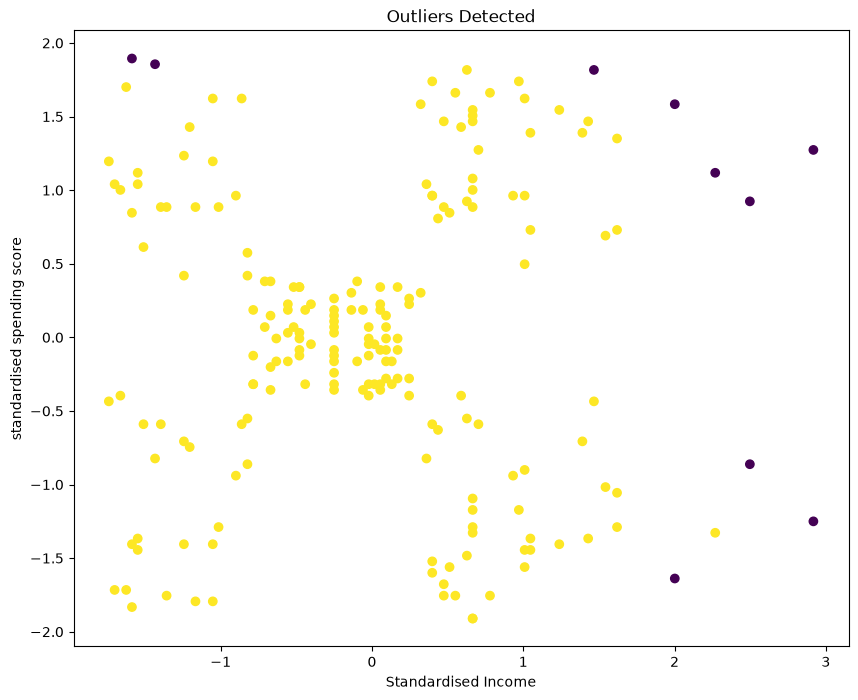

In [29]:
plt.figure(figsize =(10,8))
plt.scatter(
    X_scaled[:,0],
    X_scaled[:,1],
    c = ds['Outliers']
    )
plt.xlabel('Standardised Income')
plt.ylabel('standardised spending score')
plt.title('Outliers Detected')


### Model Inference & Business Insights

After running both **K-Means** and **Agglomerative Hierarchical Clustering**, and filtering out the anomalies using an **Isolation Forest**, we can derive actionable business intelligence from the engineered segments.

#### 1. Cluster Evaluation: K-Means vs. Hierarchical Clustering
* **K-Means Silhouette Score:** `0.555`
* **Hierarchical Clustering Silhouette Score:** `0.493`

**Inference:** The **K-Means model is the superior choice** for this dataset. The higher silhouette score indicates that partitioning the market into 5 clusters creates much tighter intra-cluster groupings and clearer behavioral boundaries than the 4-cluster structure suggested by the hierarchical dendrogram.

---

#### 2. K-Means Customer Persona Breakdown

By evaluating the mean income and spending scores across the 5 K-Means clusters, we can define the following consumer personas:

* **Cluster 0: "The Baseline Bulk" (Moderate Income, Moderate Spend)**
  * *Metrics:* ~\$55.3k Income | ~49.5 Spend Score | **81 Customers**
  * *Insight:* This is the largest segment (40.5% of the market). They are stable, middle-class shoppers who form the reliable backbone of steady store traffic.
  * *Strategy:* Focus on retention. Engage them with regular newsletter updates, rewards programs, and standard seasonal promotions.

* **Cluster 1: "The VIP Elite" (High Income, High Spend)**
  * *Metrics:* ~\$86.5k Income | ~82.1 Spend Score | **39 Customers**
  * *Insight:* The most lucrative segment. They have both high purchasing power and a strong willingness to spend on luxury and experiences.
  * *Strategy:* Maximize value through exclusive loyalty rewards, private shopping events, early access to premium products, and personalized concierge services.

* **Cluster 2: "The Impulsive Shoppers" (Low Income, High Spend)**
  * *Metrics:* ~\$25.7k Income | ~79.4 Spend Score | **22 Customers**
  * *Insight:* Young or heavily trend-driven shoppers. Despite lower financial stability, they prioritize immediate satisfaction and fashion over budget restrictions.
  * *Strategy:* Utilize FOMO (Fear Of Missing Out) marketing, flash sales, low-ticket impulse buys, and flexible payment methods (like Buy Now, Pay Later options).

* **Cluster 3: "The Untapped Affluent" (High Income, Low Spend)**
  * *Metrics:* ~\$88.2k Income | ~17.1 Spend Score | **35 Customers**
  * *Insight:* Affluent but highly calculated or pragmatic consumers. They have money but are disciplined savers who only buy if they perceive incredible value or utility.
  * *Strategy:* Avoid trendy or superficial pitches. Focus marketing on product longevity, structural value, extensive guarantees, and practical investment benefits.

* **Cluster 4: "The Cautious Spenders" (Low Income, Low Spend)**
  * *Metrics:* ~\$26.3k Income | ~20.9 Spend Score | **23 Customers**
  * *Insight:* Economically constrained consumers who shop strictly out of necessity or during steep price drops.
  * *Strategy:* Minimize high-cost acquisition spend here. Keep them mapped via broad public discount events and value/clearance tier notifications.
